In [1]:
# import necessary libraries
from pathlib import Path
from contextlib import ExitStack
from collections import Counter, defaultdict
import warnings
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits
from scipy.ndimage import median_filter
from matplotlib.colors import AsinhNorm

# Run from either the repository root or project/.
project_dir = Path.cwd() if Path("data/big_void_galaxy").is_dir() else Path.cwd() / "project"
data_dir = project_dir / "data/big_void_galaxy/2026-10-06"
output_root = project_dir / "calibration"
output_root.mkdir(exist_ok=True)
MASTERS_EXIST = True  # Set False to rebuild the masters and pixel masks.
run_all_science = False  # Older single-frame example section; the new section always uses all usable frames.
row_chunk = 128  # Keep the full-resolution median stacks within memory.
allow_missing_readout = True  # Provisional use authorized; record gaps in the FITS headers.
temperature_tolerance = 0.5  # Maximum detector-temperature difference, in degrees C.
mask_sigma = 8.0
flat_outlier_floor = 0.20  # At least 20% above the local flat response.


def read_image(path):
    return fits.getdata(path, memmap=False).astype(np.float32)


def exposure(header):
    return float(header["EXPTIME"])

min_flat_signal = 500.0  # Conservative ADU quality floor; flag weak flats for review.

# Light-frame reduction parameters (use the repository .venv Python kernel).
# Install dependencies with: .venv/bin/python -m pip install -r project/requirements-pipeline.txt
light_output_dir = project_dir / "reduction"
KEEP_CALIBRATED_LIGHTS = False  # Remove only new calibrated intermediates after verified registration.
KEEP_REGISTERED_NOISE = False  # Retain registered SCI; aggregate error maps into the final stacks.
FITS_GZIP_LEVEL = 1  # Fast, lossless compression; no floating-point quantization.
FITS_TILE_ROWS = 16
light_parameters = {
    # Reuse only products whose inputs and parameters still match.
    "reuse": True,
    "allow_weak_m33_g": True,  # Provisional use requested; flags/errors remain visible.
    "chunk_rows": 64,
    "saturation_adu": 65535,
    "random_seed": 6503,
    # Numerical gain must be in electrons/ADU. FITS headers take priority over estimates.
    # Current paired-flat estimates: e24 0.3303; refractor 1x1 0.3961; refractor 3x3 0.3838.
    # Current read noise (bias-stack STD): e24 3.63; refractor 1x1 6.79; 3x3 22.66 ADU.
    # These are reference values; Step 1 recomputes/caches the estimates from the inputs.
    "gain_header_keys": ["EGAIN", "GAIN", "CCDGAIN"],
    "gain_overrides": {"e24_1x1": None, "refractor_1x1": None, "refractor_3x3": None},
    "gain_agreement": 0.05,
    "gain_bounds": [0.001, 100.0],
    "gain_patch_size": 512,
    "gain_highpass_size": 51,
    # Uncertainty of median masters uses the Gaussian pi/(2*N) approximation.
    "normalization_stride": 32,
    "flat_apertures": 500,
    "flat_aperture_unbinned": {"e24": 25, "refractor": 24},
    # Match stars to a measured reference WCS; never use pointing alone as a solution.
    "detection_size": 2500,
    "detection_sigma": 5.0,
    "star_max_radius": 6.0,
    "star_axis_ratio": 2.5,
    "max_stars": 300,
    "control_points": 80,
    "min_matches": 12,
    "match_radius_pixels": 6.0,  # In reference-image pixels.
    "sip_degree": 2,
    "wcs_clip_iterations": 4,
    "wcs_clip_sigma": 4.0,
    "wcs_clip_floor": 0.5,
    "max_wcs_rms": 2.0,  # In native input-image pixels.
    "search_radius_deg": 2.0,
    "astrometry_scale": 6,  # 5206 index, HEALPix nside=2.
    "solve_logodds": 100.0,
    # WCS grid footprint in native reference pixels: (ymin, ymax, xmin, xmax).
    # The approved NGC crop contains the galaxy and all existing science/sky apertures.
    "grid_bounds": {"ngc6503": [2500, 6000, 4000, 8500], "m33": None},
    # Grid = solved NGC reference, or M33 r 1x1 reference (finest available sampling).
    # Reprojection is bilinear with pixel-area scaling; VARIND uses squared weights.
    "iqr_multiplier": 2.5,  # Reject outside median +/- 2.5*IQR, then take the mean.
}
# No dark subtraction. Noise/gain estimates and their sources print in Step 1 below.
# ERROR maps are diagonal, linearized pixel errors with a conservative shared-master bound.
# Resampling correlates neighboring pixels; use blank apertures for final aperture errors.


In [2]:
# load NGC 6503 and M33 fits; keep the two cameras and both refractor binnings separate

def fits_paths(folder):
    return sorted(p for p in folder.rglob("*")
                  if p.is_file() and p.suffix.lower() in {".fit", ".fits", ".fts"})


science_headers = {p: fits.getheader(p) for folder in
                   (data_dir, project_dir / "data/m33") for p in fits_paths(folder)}
calibration_headers = {p: fits.getheader(p) for p in fits_paths(project_dir / "data")
                       if any(k in fits.getval(p, "IMAGETYP").lower()
                              for k in ("bias", "flat"))}
configuration_keys = ("NAXIS1", "NAXIS2", "XBINNING", "YBINNING", "XORGSUBF",
                      "YORGSUBF", "INSTRUME", "TELESCOP", "SET-TEMP")


def object_name(header):
    return header.get("OBJECT", "").replace(" ", "").replace("-", "").upper()


setups = {}
for name, telescope, target, binning in (
    ("e24_1x1", "Elliot 24in and QHY461 CMOS", {"NGC6503"}, 1),
    ("refractor_1x1", "Astro-Tech 90mm CFT and QHY533m CMOS", {"NGC598", "M33"}, 1),
    ("refractor_3x3", "Astro-Tech 90mm CFT and QHY533m CMOS", {"NGC598", "M33"}, 3),
):
    paths = [p for p, h in science_headers.items()
             if "light" in h.get("IMAGETYP", "").lower() and object_name(h) in target
             and h.get("TELESCOP") == telescope
             and h.get("XBINNING") == h.get("YBINNING") == binning]
    if not paths:
        raise ValueError(f"No science frames for {name}.")
    mode = Counter(science_headers[p].get("READOUTM") for p in paths).most_common(1)[0][0]
    ref = next(science_headers[p] for p in paths if science_headers[p].get("READOUTM") == mode)
    setups[name] = dict(reference=ref, shape=(ref["NAXIS2"], ref["NAXIS1"]),
                       output_dir=output_root / name, candidates=paths)


def compatible(header, setup):
    ref = setup["reference"]
    if any(header.get(k) != ref.get(k) for k in configuration_keys):
        return False
    if abs(float(header["CCD-TEMP"]) - float(ref["CCD-TEMP"])) > temperature_tolerance:
        return False
    modes = (header.get("READOUTM"), ref.get("READOUTM"))
    if None in modes:
        return allow_missing_readout or modes == (None, None)
    return modes[0] == modes[1]


for name, setup in setups.items():
    setup["science_paths"] = [p for p in setup.pop("candidates") if compatible(science_headers[p], setup)]
    setup["output_dir"].mkdir(exist_ok=True)
    print(name, setup["shape"], Counter(science_headers[p]["FILTER"] for p in setup["science_paths"]))
# OBJECT is authoritative: some NGC-6503 filenames actually contain PGC 71538.


e24_1x1 (8748, 11664) Counter({"g'": 10, "i'": 9, "r'": 9})
refractor_1x1 (3008, 3008) Counter({'r': 10, 'g': 1})
refractor_3x3 (1002, 1002) Counter({'g': 10, 'i': 10})


In [3]:
# load matching measured flats and biases; dark subtraction is omitted by design
for name, setup in setups.items():
    setup["bias_paths"], setup["flat_paths"] = [], []
    for path, header in calibration_headers.items():
        if not compatible(header, setup):
            continue
        kind = header["IMAGETYP"].lower()
        if "bias" in kind:
            if exposure(header) != 0:
                raise ValueError(f"Nonzero bias exposure: {path}")
            setup["bias_paths"].append(path)
        elif "flat" in kind:
            setup["flat_paths"].append(path)
    if not setup["bias_paths"] or not setup["flat_paths"]:
        raise ValueError(f"Missing bias/flat data for {name}.")
    flat_groups = defaultdict(list)
    for path in setup["flat_paths"]:
        flat_groups[calibration_headers[path]["FILTER"]].append(path)
    setup["flat_groups"] = dict(flat_groups)
    inputs = setup["bias_paths"] + setup["flat_paths"] + setup["science_paths"]
    setup["missing_readout"] = any(fits.getheader(p).get("READOUTM") is None for p in inputs)
    if setup["missing_readout"]:
        warnings.warn(f"{name}: READOUTM missing in some inputs; camera/gain compatibility is provisional.")
    print(f"{name}: {len(setup['bias_paths'])} biases; flats "
          f"{ {band: len(paths) for band, paths in flat_groups.items()} }")
    missing = {science_headers[p]["FILTER"] for p in setup["science_paths"]} - flat_groups.keys()
    if missing:
        raise ValueError(f"No matching flats for {name}: {missing}")
# Never resize a flat or mask to another binning; use its matching raw calibrations.


e24_1x1: 30 biases; flats {"g'": 10, "i'": 10, "r'": 10}
refractor_1x1: 20 biases; flats {'g': 5, 'r': 10}
refractor_3x3: 20 biases; flats {'g': 5, 'i': 10}


/var/folders/71/1_qbn7zs34z0yclndvvgww7h0000gp/T/ipykernel_74168/3128871260.py:23: UserWarning: e24_1x1: READOUTM missing in some inputs; camera/gain compatibility is provisional.
  warnings.warn(f"{name}: READOUTM missing in some inputs; camera/gain compatibility is provisional.")
/var/folders/71/1_qbn7zs34z0yclndvvgww7h0000gp/T/ipykernel_74168/3128871260.py:23: UserWarning: refractor_1x1: READOUTM missing in some inputs; camera/gain compatibility is provisional.
  warnings.warn(f"{name}: READOUTM missing in some inputs; camera/gain compatibility is provisional.")
/var/folders/71/1_qbn7zs34z0yclndvvgww7h0000gp/T/ipykernel_74168/3128871260.py:23: UserWarning: refractor_3x3: READOUTM missing in some inputs; camera/gain compatibility is provisional.
  warnings.warn(f"{name}: READOUTM missing in some inputs; camera/gain compatibility is provisional.")


In [4]:
# create median-combined biases/flats and provisional hot-pixel masks
# No dark correction: science = (light - bias) / normalized(flat - bias).
def median_combine(paths, image_shape, bias=None, scales=None):
    combined = np.empty(image_shape, dtype=np.float32)
    scales = np.ones(len(paths), dtype=np.float32) if scales is None else np.asarray(scales, dtype=np.float32)
    with ExitStack() as stack:
        hdus = [stack.enter_context(fits.open(p, memmap=False)) for p in paths]
        for y in range(0, image_shape[0], row_chunk):
            rows = slice(y, min(y + row_chunk, image_shape[0]))
            strips = []
            for hdu, scale in zip(hdus, scales):
                strip = hdu[0].section[rows, :].astype(np.float32)
                if bias is not None:
                    # Ignore saturated/nonfinite pixels without discarding a whole flat.
                    invalid = ~np.isfinite(strip) | (strip >= 65535)
                    strip -= bias[rows]
                    strip[invalid] = np.nan
                strips.append(strip / scale)
            with warnings.catch_warnings():
                warnings.filterwarnings("ignore", message="All-NaN slice encountered")
                cube = np.stack(strips)
                combine = np.median if np.isfinite(cube).all() else np.nanmedian
                combined[rows] = combine(cube, axis=0, overwrite_input=True)
    return combined


def save_master(data, filename, kind, paths, setup, unit="adu", **keywords):
    header = fits.Header()
    for key in configuration_keys + ("CCD-TEMP", "READOUTM"):
        if key in setup["reference"]:
            header[key] = setup["reference"][key]
    header["IMAGETYP"], header["BUNIT"] = kind, unit
    header["NCOMBINE"], header["SYNTHET"] = len(paths), False
    header["RDMISS"] = setup["missing_readout"]
    header["DARKCOR"] = False
    if setup["missing_readout"]:
        header.add_history("Provisional calibration: some input READOUTM values missing.")
    for key, value in keywords.items():
        header[key] = value
    for path in paths:
        header.add_history(f"Input: {path.name}")
    fits.writeto(setup["output_dir"] / filename, data, header, overwrite=True)
    print(f"Saved {setup['output_dir'].name}/{filename} ({len(paths)} inputs)", flush=True)


def local_residual(image):
    # Include neighboring rows at chunk boundaries; avoid a second full-size smoothed image.
    residual = np.empty_like(image)
    for y in range(0, image.shape[0], row_chunk):
        stop = min(y + row_chunk, image.shape[0])
        start, end = max(0, y - 1), min(image.shape[0], stop + 1)
        patch = image[start:end].copy()
        finite = np.isfinite(patch)
        patch[~finite] = np.nanmedian(patch)
        smooth = median_filter(patch, size=3, mode="reflect")
        residual[y:stop] = image[y:stop] - smooth[y-start:stop-start]
    return residual


def robust_sigma(values):
    values = values[np.isfinite(values)]
    center = np.median(values)
    return float(1.4826 * np.median(np.abs(values - center)))


if MASTERS_EXIST:
    # Reuse the saved products, including their flat-quality flags.
    for name, setup in setups.items():
        setup["flat_files"], setup["low_signal_flats"] = {}, set()
        for band in setup["flat_groups"]:
            safe_band = "".join(c for c in band if c.isalnum())
            setup["flat_files"][band] = setup["output_dir"] / f"master_flat_{safe_band}.fit"
        required = [setup["output_dir"] / filename for filename in
                    ("master_bias.fit", "hot_pixel_mask.fit", "bad_pixel_mask.fit")]
        required += list(setup["flat_files"].values())
        for path in required:
            if not path.is_file():
                raise FileNotFoundError(f"Missing calibration product: {path}. "
                                        "Set MASTERS_EXIST = False to rebuild.")
            header = fits.getheader(path)
            if not compatible(header, setup):
                raise ValueError(f"Incompatible saved calibration: {path}. "
                                 "Set MASTERS_EXIST = False to rebuild.")
            setup["missing_readout"] |= bool(header.get("RDMISS", False))
        for band, path in setup["flat_files"].items():
            header = fits.getheader(path)
            if header["FILTER"] != band:
                raise ValueError(f"Wrong filter in saved master flat: {path}")
            if header["FLATLOW"]:
                setup["low_signal_flats"].add(band)
        print(f"{name}: reusing saved bias, flats, and pixel masks; "
              f"low-signal filters: {sorted(setup['low_signal_flats'])}")
else:
    for name, setup in setups.items():
        shape = setup["shape"]
        master_bias = median_combine(setup["bias_paths"], shape)
        assert np.isfinite(master_bias).all()
        save_master(master_bias, "master_bias.fit", "Master Bias", setup["bias_paths"], setup, EXPTIME=0.0)
        # Check a patch against an independent direct median of the raw inputs.
        with ExitStack() as stack:
            hdus = [stack.enter_context(fits.open(p, memmap=False)) for p in setup["bias_paths"]]
            expected = np.median(np.stack([h[0].section[:16, :16] for h in hdus]), axis=0)
        np.testing.assert_array_equal(master_bias[:16, :16], expected)
        residual = local_residual(master_bias)
        bias_threshold = max(10.0, mask_sigma * robust_sigma(residual[::8, ::8]))
        hot_mask = residual > bias_threshold
        del residual
        bad_mask = hot_mask.copy()
        setup["flat_files"], setup["low_signal_flats"] = {}, set()
        for band, paths in sorted(setup["flat_groups"].items()):
            scales = []
            for path in paths:
                raw = read_image(path)
                valid = np.isfinite(raw) & (raw < 65535)
                raw -= master_bias
                # Zero/negative regions are invalid response, not illumination estimates.
                valid &= raw > 0
                if np.count_nonzero(valid) < 0.5 * raw.size:
                    raise ValueError(f"Flat has too few usable pixels: {path}")
                scale = float(np.median(raw[valid]))
                if not np.isfinite(scale) or scale <= 0:
                    raise ValueError(f"Nonpositive flat signal: {path}")
                scales.append(scale)
                del raw, valid
            signal = float(np.median(scales))
            low_signal = signal < min_flat_signal
            if low_signal:
                setup["low_signal_flats"].add(band)
                warnings.warn(f"{name} {band}: flat signal only {signal:g} ADU above bias; "
                              "save for review, omit from detector masks, and block science use by default.")
            flat = median_combine(paths, shape, master_bias, scales)
            valid = np.isfinite(flat) & (flat > 0)
            flat /= np.median(flat[valid])
            residual = local_residual(flat)
            threshold = max(flat_outlier_floor, mask_sigma * robust_sigma(residual[::8, ::8]))
            if not low_signal:
                hot_mask |= residual > threshold
                # Weak flats cannot distinguish detector defects from noise.
                bad_mask |= ~valid | (flat < 0.5) | (flat > 1.5) | (np.abs(residual) > threshold)
            flat[~valid] = np.nan
            safe_band = "".join(c for c in band if c.isalnum())
            filename = f"master_flat_{safe_band}.fit"
            setup["flat_files"][band] = setup["output_dir"] / filename
            save_master(flat, filename, "Master Flat", paths, setup, unit="relative",
                        FILTER=band, BIASCOR=True, COMBMETH="MEDIAN", FLTNORM=True,
                        FLATLOW=low_signal, FLATSIG=signal, MINFLAT=min_flat_signal)
            assert np.isclose(np.nanmedian(flat), 1, atol=1e-6)
            # Independent normalized flat check at a real-data patch.
            with ExitStack() as stack:
                hdus = [stack.enter_context(fits.open(p, memmap=False)) for p in paths]
                patch = np.stack([(h[0].section[:16, :16].astype(np.float32) - master_bias[:16, :16]) / s
                                  for h, s in zip(hdus, scales)])
            # Full-frame normalization is common to all pixels; compare relative patch values.
            expected = np.median(patch, axis=0)
            good = np.isfinite(flat[:16, :16]) & (expected > 0)
            if np.any(good):
                ratio = flat[:16, :16][good] / expected[good]
                np.testing.assert_allclose(ratio, np.median(ratio), rtol=2e-6)
            del flat, residual
        bad_mask |= hot_mask
        # Bias/median-flat outliers are candidates; dark-current hot pixels are not measured.
        mask_inputs = setup["bias_paths"] + [p for p in setup["flat_paths"]
                       if calibration_headers[p]["FILTER"] not in setup["low_signal_flats"]]
        for filename, data, kind in (("hot_pixel_mask.fit", hot_mask, "Hot Pixel Mask"),
                                     ("bad_pixel_mask.fit", bad_mask, "Bad Pixel Mask")):
            save_master(data.astype(np.uint8), filename, kind, mask_inputs, setup, unit="mask",
                        PROVIS=True, MASKSIG=mask_sigma, BIASTHR=bias_threshold,
                        FLTFLOOR=flat_outlier_floor, MASKN=int(data.sum()),
                        MASKMETH="BIAS+FLAT", MASKTRUE="1=exclude")
        print(f"{name}: {hot_mask.sum()} hot candidates, {bad_mask.sum()} total bad pixels", flush=True)
        del master_bias, hot_mask, bad_mask

    print("Median products and independent raw-pixel checks passed.")


e24_1x1: reusing saved bias, flats, and pixel masks; low-signal filters: []
refractor_1x1: reusing saved bias, flats, and pixel masks; low-signal filters: ['g']
refractor_3x3: reusing saved bias, flats, and pixel masks; low-signal filters: ['g']


In [5]:
# Calibrate frames with the matching camera, binning, filter, bias, and mask.
# Missing readout metadata remains explicitly flagged; dark subtraction is omitted.
def calibrate_frame(path, save=False, allow_low_signal=False):
    header = fits.getheader(path)
    matches = [s for s in setups.values() if compatible(header, s)]
    if len(matches) != 1:
        raise ValueError(f"Science frame has no unique calibration setup: {path}")
    setup = matches[0]
    flat_path = setup["flat_files"].get(header["FILTER"])
    if flat_path is None:
        raise ValueError(f"Missing measured flat for {path}")
    low_signal = header["FILTER"] in setup["low_signal_flats"]
    if low_signal and not allow_low_signal:
        raise ValueError(f"Low-signal flat for {path}; obtain better g flats or explicitly "
                         "set allow_low_signal=True for provisional exploration.")
    corrected = read_image(path) - read_image(setup["output_dir"] / "master_bias.fit")
    corrected /= read_image(flat_path)
    mask_path = setup["output_dir"] / "bad_pixel_mask.fit"
    corrected[fits.getdata(mask_path, memmap=False).astype(bool)] = np.nan
    header["BUNIT"], header["BIASCOR"], header["DARKCOR"] = "adu", True, False
    header["FLATCOR"], header["SYNTHET"], header["MASKCOR"] = True, False, True
    header["RDMISS"], header["MASKPROV"] = setup["missing_readout"], True
    header["FLATLOW"] = low_signal
    if low_signal:
        header.add_history("WARNING: low-signal flat explicitly allowed; unsuitable for final photometry.")
    header.add_history("Correction: (raw - median bias) / normalized median(flat - bias).")
    header.add_history("Dark subtraction omitted; provisional bias/flat bad pixels set to NaN.")
    if setup["missing_readout"]:
        header.add_history("Provisional: some input READOUTM metadata missing.")
    for filename in ("master_bias.fit", flat_path.name, mask_path.name):
        header.add_history(f"Calibration: {setup['output_dir'].name}/{filename}")
    if save:
        fits.writeto(setup["output_dir"] / f"{path.stem}_calibrated.fit", corrected, header, overwrite=True)
    return corrected, header


# Save one example per telescope/binning. Enable the loop to save all science frames.
for name, setup in setups.items():
    usable = [p for p in setup["science_paths"]
              if science_headers[p]["FILTER"] not in setup["low_signal_flats"]]
    skipped = len(setup["science_paths"]) - len(usable)
    if skipped:
        print(f"{name}: withholding {skipped} science frames with low-signal flats.")
    paths = usable if run_all_science else usable[:1]
    for path in paths:
        corrected, header = calibrate_frame(path, save=True)
        assert corrected.shape == setup["shape"]
        assert header["FLATCOR"] and header["MASKCOR"] and not header["DARKCOR"]
        del corrected

# Retain the NGC 6503 variables used in the existing analysis below.
ngc_setup = setups["e24_1x1"]
science_paths = ngc_setup["science_paths"]
bias_paths = ngc_setup["bias_paths"]
shape, output_dir = ngc_setup["shape"], ngc_setup["output_dir"]
master_bias = read_image(output_dir / "master_bias.fit")
master_flats = {band: read_image(path) for band, path in ngc_setup["flat_files"].items()}
example_path = next(p for p in science_paths if science_headers[p]["FILTER"] == "g'")
calibrated_image, calibrated_header = calibrate_frame(example_path, save=True)
print({k: calibrated_header[k] for k in ("BIASCOR", "DARKCOR", "FLATCOR", "SYNTHET", "MASKCOR", "RDMISS")})


refractor_1x1: withholding 1 science frames with low-signal flats.
refractor_3x3: withholding 10 science frames with low-signal flats.


{'BIASCOR': True, 'DARKCOR': False, 'FLATCOR': True, 'SYNTHET': False, 'MASKCOR': True, 'RDMISS': True}


## Registering and stacking light frames

In [6]:
# Step 1: estimate gain/read noise and the uncertainties of the existing masters.
# Header gains are checked first. Otherwise use paired well-illuminated flats.
# Save the PDF bias-STD map and 500-aperture flat diagnostic as well.
import sys
if str(project_dir) not in sys.path:
    sys.path.insert(0, str(project_dir))
import light_reduction
light_reduction.FITS_GZIP_LEVEL = FITS_GZIP_LEVEL
light_reduction.FITS_TILE_ROWS = FITS_TILE_ROWS
from light_reduction import (calibration_models, calibrate_exposures, register_exposures,
                             stack_exposures, propagate_stack_errors)

light_output_dir.mkdir(exist_ok=True)
noise_models = calibration_models(setups, light_output_dir, light_parameters)
for name, model in noise_models.items():
    print(f"{name}: gain = {model['gain']:.4g} e-/ADU ({model['gain_source']}), "
          f"read noise = {model['read_noise_adu']:.3g} ADU = {model['read_noise_electrons']:.3g} e-")


e24_1x1: reusing calibration uncertainty maps


refractor_1x1: reusing calibration uncertainty maps


refractor_3x3: reusing calibration uncertainty maps


e24_1x1: gain = 0.3303 e-/ADU (PAIRED_FLATS), read noise = 3.63 ADU = 1.2 e-
refractor_1x1: gain = 0.3961 e-/ADU (PAIRED_FLATS), read noise = 6.79 ADU = 2.69 e-
refractor_3x3: gain = 0.3838 e-/ADU (PAIRED_FLATS), read noise = 22.7 ADU = 8.7 e-


In [7]:
# Step 2: calibrate every usable exposure and propagate detector/calibration errors.
# Divide (light - bias) by the normalized bias-subtracted flat and exposure time.
# Deliberately include the weak M33 g flats for now; those products are provisional.
# VARIND = shot + read-noise variance. CALSIG = shared bias/flat uncertainty.
calibrated_exposures = calibrate_exposures(setups, noise_models, light_output_dir, light_parameters)
print(f"Calibrated {len(calibrated_exposures)} exposures; units are ADU/s per native pixel.")


Calibrated e24_1x1: NGC-6503_LIGHT_g'_1x1_120.000secs_00000100.fit


Calibrated e24_1x1: NGC-6503_LIGHT_g'_1x1_120.000secs_00000101.fit


Calibrated e24_1x1: NGC-6503_LIGHT_g'_1x1_120.000secs_00000102.fit


Calibrated e24_1x1: NGC-6503_LIGHT_g'_1x1_120.000secs_00000103.fit


Calibrated e24_1x1: NGC-6503_LIGHT_g'_1x1_120.000secs_00000104.fit


Calibrated e24_1x1: NGC-6503_LIGHT_g'_1x1_120.000secs_00000105.fit


... (50 outputs left out)

Calibrated refractor_3x3: M-33NGC 598_i_3x3_00001090.fit


Calibrated refractor_3x3: M-33NGC 598_i_3x3_00001091.fit


Calibrated refractor_3x3: M-33NGC 598_i_3x3_00001092.fit


Calibrated 59 exposures; units are ADU/s per native pixel.


In [8]:
# Step 3: solve/transfer a WCS for each exposure, then register onto a common sky grid.
# Astrometry.net solves M33's reference; the existing NGC 6503 WCS anchors that galaxy.
# Star matches fit each exposure's WCS; reproject puts all bands on the same grid.
# Preserve flux units with the output/input pixel-area ratio and propagate masks.
registered_exposures = register_exposures(calibrated_exposures, light_output_dir,
                                         project_dir, light_parameters,
                                         keep_calibrated=KEEP_CALIBRATED_LIGHTS)
print(f"Registered {len(registered_exposures)} exposures, with WCS match/RMS checks.")

# Calibrated intermediates may be removed here; validated registered products are cached.


Registered NGC-6503_LIGHT_g'_1x1_120.000secs_00000100.fit: 257 stars, RMS 0.216 native pixels


Registered NGC-6503_LIGHT_g'_1x1_120.000secs_00000101.fit: 254 stars, RMS 0.232 native pixels


Registered NGC-6503_LIGHT_g'_1x1_120.000secs_00000102.fit: 240 stars, RMS 0.227 native pixels


Registered NGC-6503_LIGHT_g'_1x1_120.000secs_00000103.fit: 241 stars, RMS 0.237 native pixels


Registered NGC-6503_LIGHT_g'_1x1_120.000secs_00000104.fit: 234 stars, RMS 0.230 native pixels


Registered NGC-6503_LIGHT_g'_1x1_120.000secs_00000105.fit: 253 stars, RMS 0.248 native pixels


... (50 outputs left out)

Registered M-33NGC 598_i_3x3_00001090.fit: 260 stars, RMS 0.216 native pixels


Registered M-33NGC 598_i_3x3_00001091.fit: 256 stars, RMS 0.227 native pixels


Registered M-33NGC 598_i_3x3_00001092.fit: 259 stars, RMS 0.214 native pixels


Registered 59 exposures, with WCS match/RMS checks.


In [9]:
# Step 4: stack each galaxy/filter using the PDF's IQR rejection rule.
# Per pixel: reject outside median +/- 2.5*IQR, then average the surviving values.
# Save SCI, sample STD, NVALID, NREJECT, and each input's rejection mask.
# No-coverage pixels stay NaN; the actual number of contributing exposures is used.
stack_products = stack_exposures(registered_exposures, light_output_dir, light_parameters,
                                  keep_registered_noise=KEEP_REGISTERED_NOISE)

# Per-exposure noise maps can be compacted after their accepted-weight sums are saved.


Stacked m33 g: 11 exposures


Stacked m33 i: 10 exposures


Stacked m33 r: 10 exposures


Stacked ngc6503 g: 10 exposures


Stacked ngc6503 i: 9 exposures


Stacked ngc6503 r: 9 exposures


In [10]:
# Step 5: propagate uncertainties through the accepted stack samples.
# Independent variance adds with squared averaging weights. Shared master errors
# use a conservative correlation bound rather than incorrectly shrinking as 1/N.
# ERROR^2 = max(propagated random variance, STD^2/N) + shared calibration bound.
# Global flat-normalization, estimated-gain, and WCS-fit errors are not included;
# weak g-flat products and all approximation/covariance limits remain flagged.
stack_uncertainties = propagate_stack_errors(stack_products, light_output_dir, light_parameters)


Uncertainty m33 g [PROVISIONAL: weak g flat]


Uncertainty m33 i


Uncertainty m33 r


Uncertainty ngc6503 g


Uncertainty ngc6503 i


Uncertainty ngc6503 r


m33 g: median 1-sigma pixel error = 0.1298 ADU/s; shared calibration bound included.


m33 i: median 1-sigma pixel error = 0.08145 ADU/s; shared calibration bound included.


m33 r: median 1-sigma pixel error = 0.1487 ADU/s; shared calibration bound included.


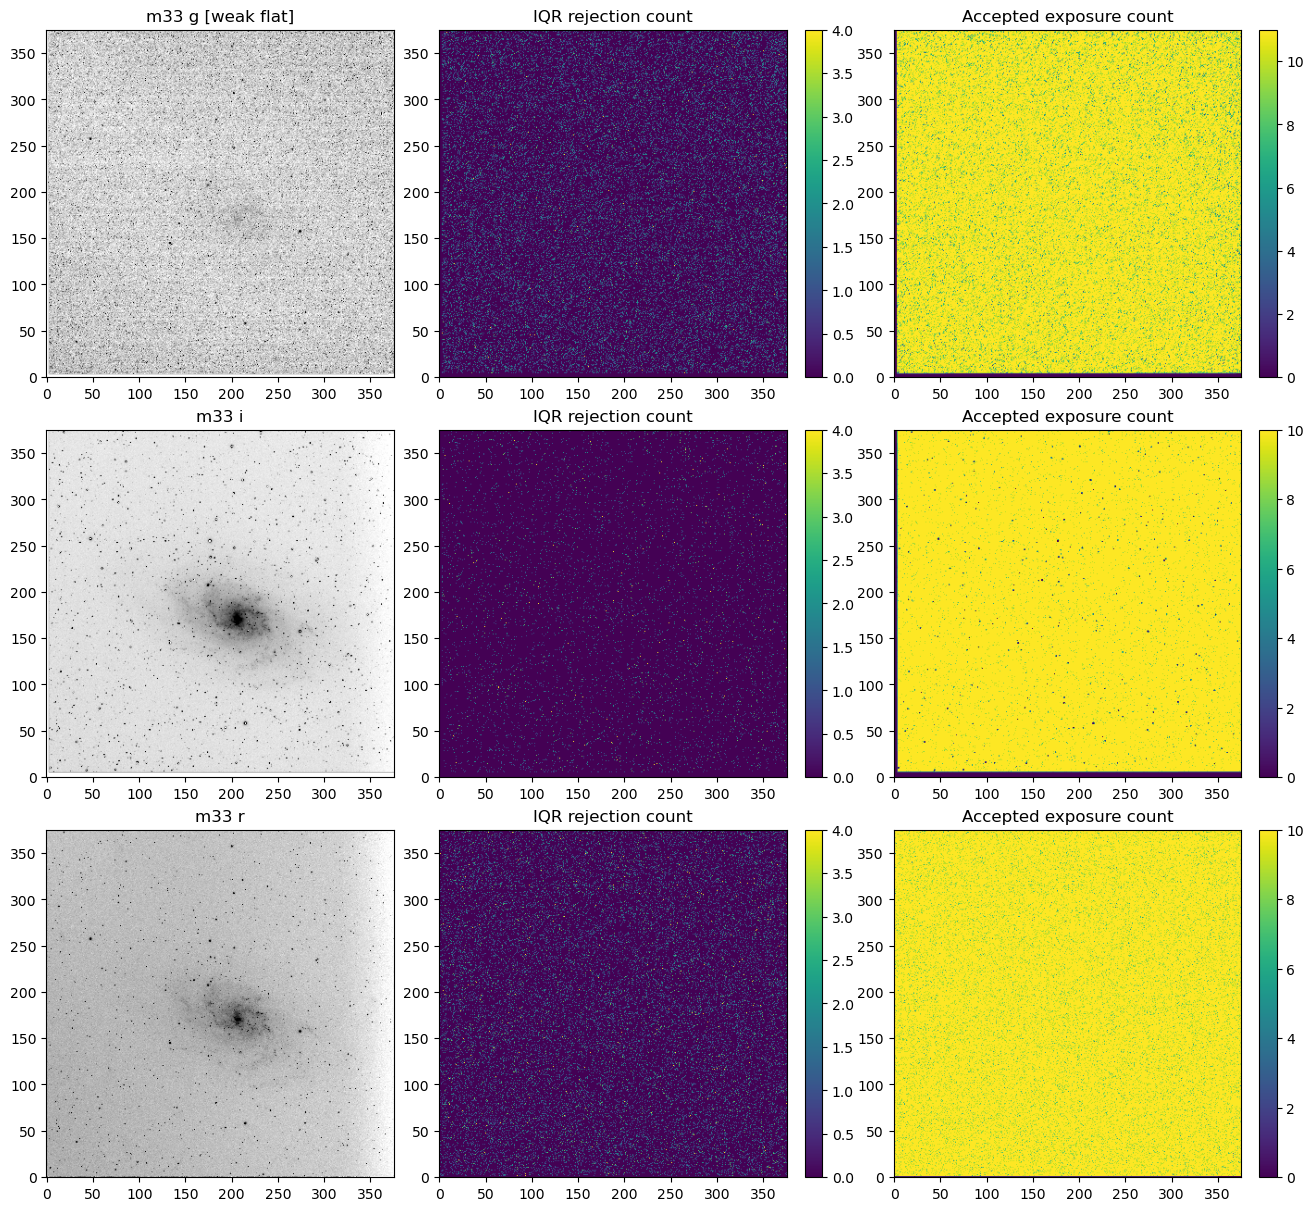

ngc6503 g: median 1-sigma pixel error = 0.05636 ADU/s; shared calibration bound included.


ngc6503 i: median 1-sigma pixel error = 0.02967 ADU/s; shared calibration bound included.


ngc6503 r: median 1-sigma pixel error = 0.04773 ADU/s; shared calibration bound included.


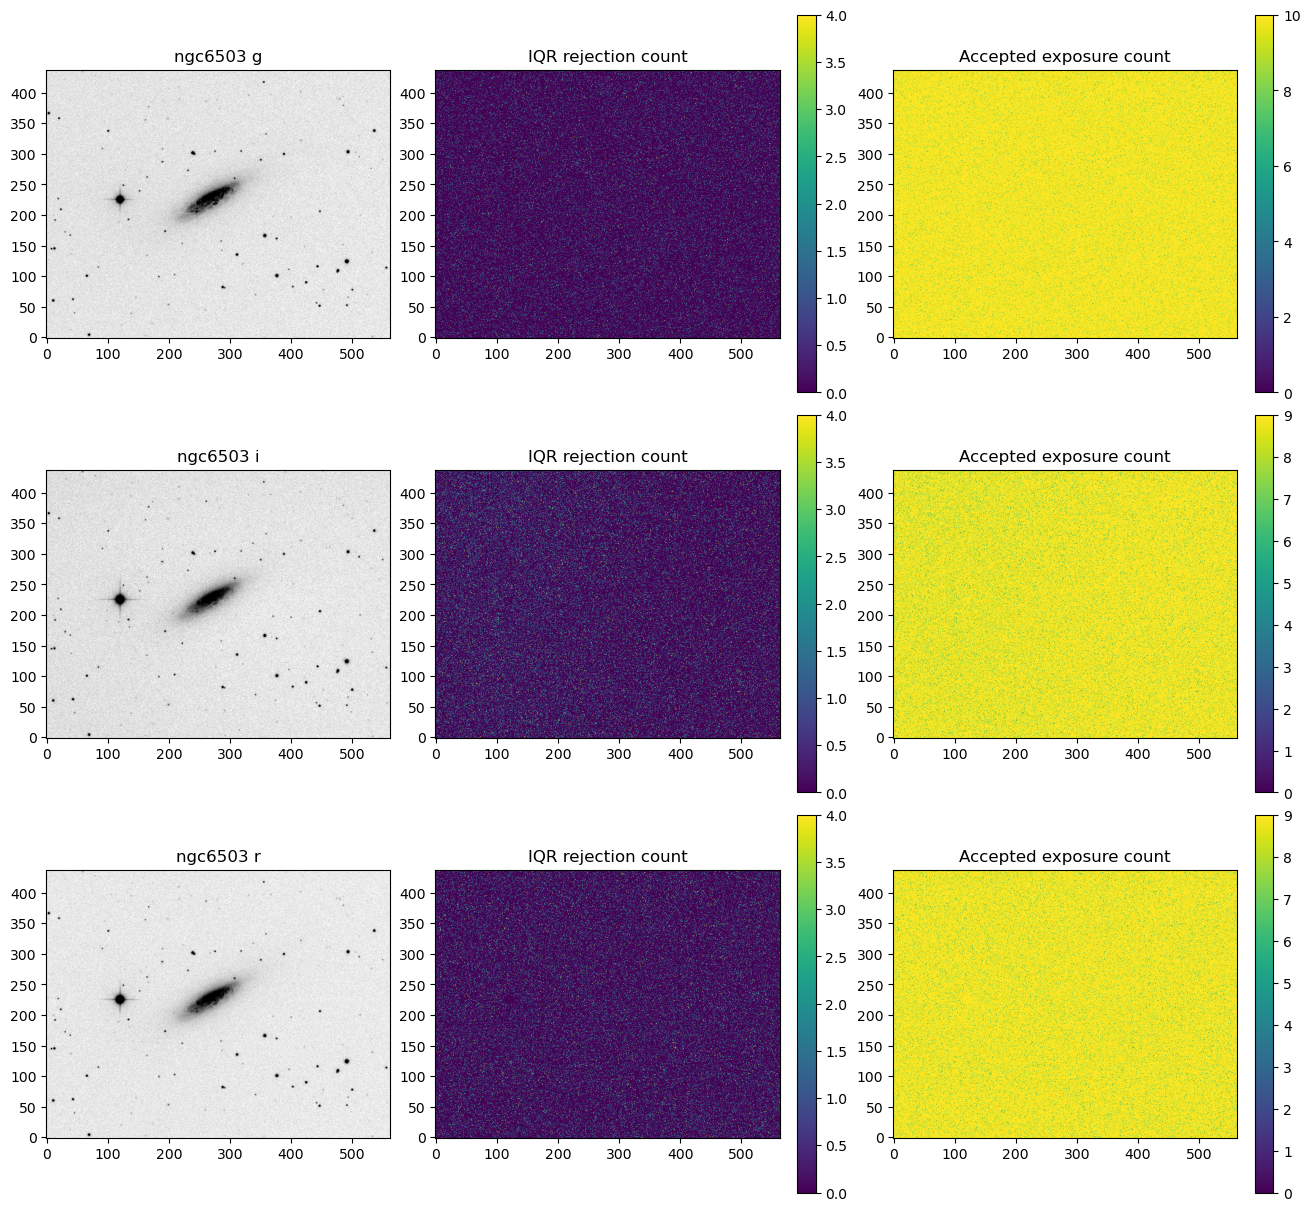

In [11]:
# Step 6: inspect stacked images, rejection maps, coverage, and uncertainty levels.
# Rejection codes: 0 = kept, 1 = rejected by IQR, 2 = invalid/no coverage.
for galaxy in sorted({key[0] for key in stack_products}):
    bands = sorted(band for name, band in stack_products if name == galaxy)
    fig, axes = plt.subplots(len(bands), 3, figsize=(13, 4*len(bands)), squeeze=False,
                             layout="constrained")
    for row, band in enumerate(bands):
        with fits.open(stack_products[(galaxy, band)], memmap=False) as h:
            image = h["SCI"].data[::8, ::8]
            reject = h["NREJECT"].data[::8, ::8]
            count = h["NVALID"].data[::8, ::8]
            lo, hi = np.nanpercentile(image, [1, 99.7])
            axes[row, 0].imshow(image, origin="lower", cmap="gray_r",
                                norm=AsinhNorm(linear_width=max((hi-lo)/10, 1e-6), vmin=lo, vmax=hi))
            axes[row, 0].set_title(f"{galaxy} {band}" + (" [weak flat]" if h[0].header["FLATLOW"] else ""))
            im = axes[row, 1].imshow(reject, origin="lower", vmin=0)
            axes[row, 1].set_title("IQR rejection count")
            fig.colorbar(im, ax=axes[row, 1])
            im = axes[row, 2].imshow(count, origin="lower", vmin=0)
            axes[row, 2].set_title("Accepted exposure count")
            fig.colorbar(im, ax=axes[row, 2])
        with fits.open(stack_uncertainties[(galaxy, band)], memmap=False) as h:
            print(f"{galaxy} {band}: median 1-sigma pixel error = "
                  f"{np.nanmedian(h['ERROR'].data):.4g} ADU/s; shared calibration bound included.")
    plt.show()
# The pre-existing Analysis section below still shows the earlier single-frame profiles.
# The registered stacks and their errors are available in stack_products/stack_uncertainties.


## Analysis

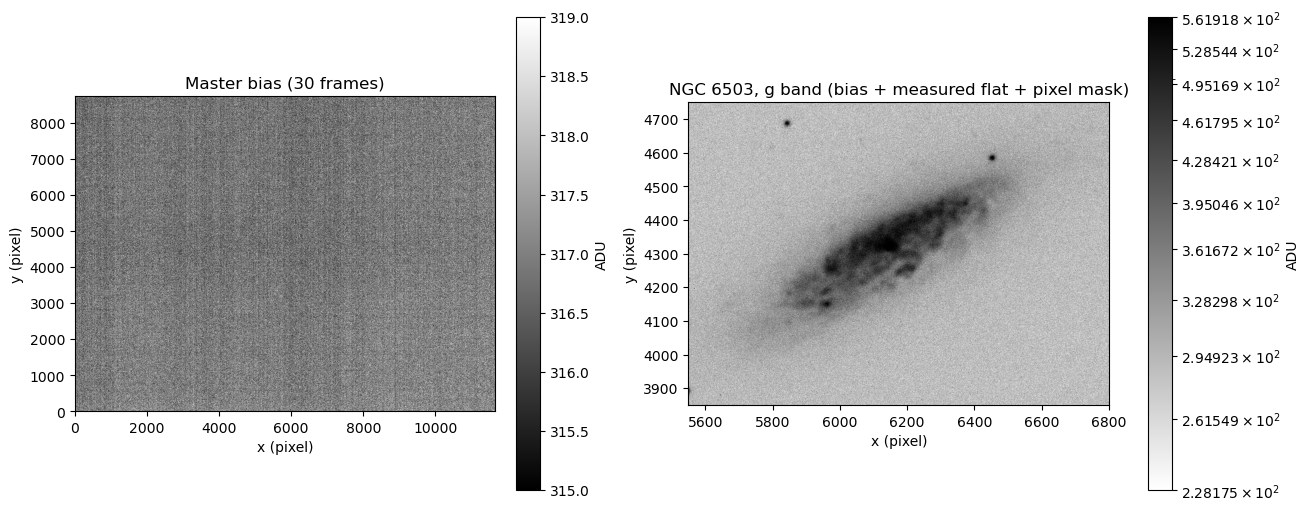

Saved FITS dimensions, flags, and science-pixel checks passed.


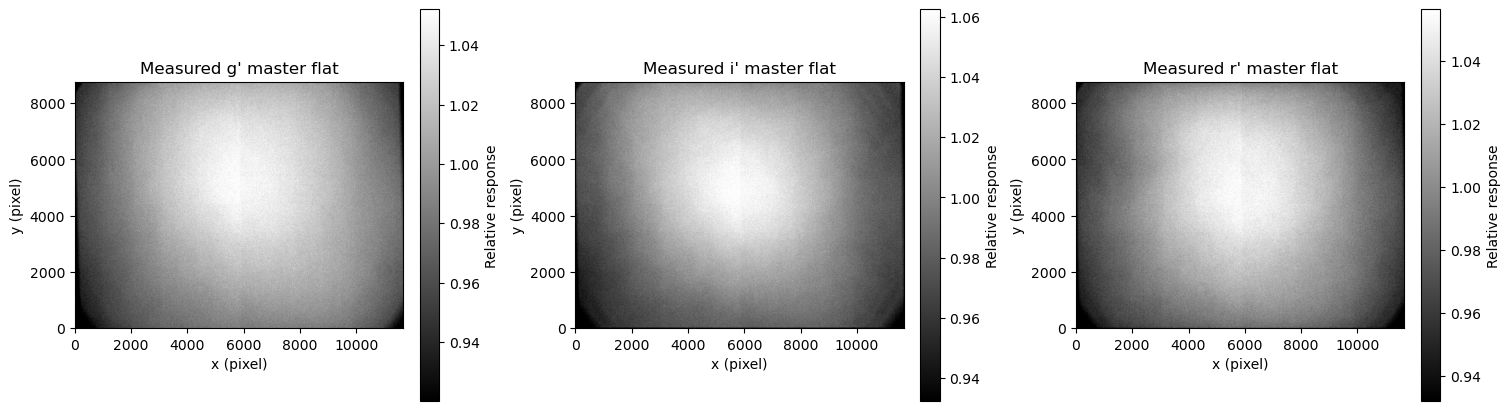

In [12]:
# Display a calibrated NGC 6503 image
# Use the galaxy crop identified in galactic_imaging.ipynb; never bin the saved data.
ymin, ymax, xmin, xmax = 3850, 4750, 5550, 6800
crop = calibrated_image[ymin:ymax, xmin:xmax]
lo, hi = np.nanpercentile(crop, [1, 99.7])
fig, axes = plt.subplots(1, 2, figsize=(13, 5), layout="constrained")
bias_preview = master_bias[::8, ::8]
blo, bhi = np.percentile(bias_preview, [1, 99])
im = axes[0].imshow(bias_preview, origin="lower", cmap="gray", vmin=blo, vmax=bhi,
                    extent=(0, shape[1], 0, shape[0]))
axes[0].set(title=f"Master bias ({len(bias_paths)} frames)", xlabel="x (pixel)", ylabel="y (pixel)")
fig.colorbar(im, ax=axes[0], label="ADU")
im = axes[1].imshow(crop, origin="lower", cmap="gray_r",
                    norm=AsinhNorm(linear_width=(hi - lo) / 10, vmin=lo, vmax=hi),
                    extent=(xmin, xmax, ymin, ymax))
status = "bias + measured flat + pixel mask"
axes[1].set(title=f"NGC 6503, g band ({status})", xlabel="x (pixel)", ylabel="y (pixel)")
fig.colorbar(im, ax=axes[1], label="ADU")
plt.show()

# Confirm saved products preserve dimensions and correction flags.
with fits.open(output_dir / "master_bias.fit", memmap=False) as hdu:
    assert hdu[0].shape == shape and hdu[0].header["NCOMBINE"] == len(bias_paths)
with fits.open(output_dir / f"{example_path.stem}_calibrated.fit", memmap=False) as hdu:
    assert hdu[0].shape == shape and hdu[0].header["BIASCOR"]
    np.testing.assert_array_equal(hdu[0].section[ymin:ymax, xmin:xmax], crop)
with fits.open(example_path, memmap=False) as hdu:
    expected = hdu[0].section[ymin:ymax, xmin:xmax].astype(np.float32) - master_bias[ymin:ymax, xmin:xmax]
example_flat = master_flats.get(calibrated_header["FILTER"])
if example_flat is not None:
    expected /= example_flat[ymin:ymax, xmin:xmax]
expected[fits.getdata(output_dir / "bad_pixel_mask.fit", memmap=False)[ymin:ymax, xmin:xmax].astype(bool)] = np.nan
np.testing.assert_array_equal(crop, expected)
print("Saved FITS dimensions, flags, and science-pixel checks passed.")

if master_flats:
    fig, axes = plt.subplots(1, len(master_flats), figsize=(5 * len(master_flats), 4),
                             squeeze=False, layout="constrained")
    for ax, (band, flat) in zip(axes[0], sorted(master_flats.items())):
        preview = flat[::16, ::16]
        lo, hi = np.nanpercentile(preview, [1, 99])
        im = ax.imshow(preview, origin="lower", cmap="gray", vmin=lo, vmax=hi,
                       extent=(0, shape[1], 0, shape[0]))
        label = "Measured"
        ax.set(title=f"{label} {band} master flat", xlabel="x (pixel)", ylabel="y (pixel)")
        fig.colorbar(im, ax=ax, label="Relative response")
    plt.show()


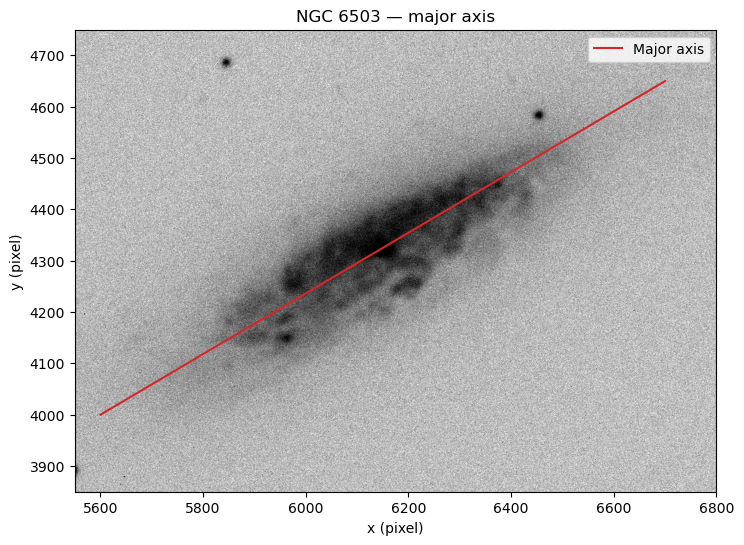

In [13]:
# Create a `construction line` along the major axis of the galaxy

axis_ends = np.array([[5600, 4000], [6700, 4650]])
axis_vector = axis_ends[1] - axis_ends[0]
axis_length = np.linalg.norm(axis_vector)
lo, hi = np.nanpercentile(crop, [1, 99.7])
fig, ax = plt.subplots(figsize=(9, 6))
ax.imshow(crop, origin="lower", cmap="gray_r", extent=(xmin, xmax, ymin, ymax),
          norm=AsinhNorm(linear_width=(hi - lo) / 10, vmin=lo, vmax=hi))
ax.plot(*axis_ends.T, color="tab:red", label="Major axis")
ax.set(xlabel="x (pixel)", ylabel="y (pixel)", title="NGC 6503 — major axis")
ax.legend()
plt.show()


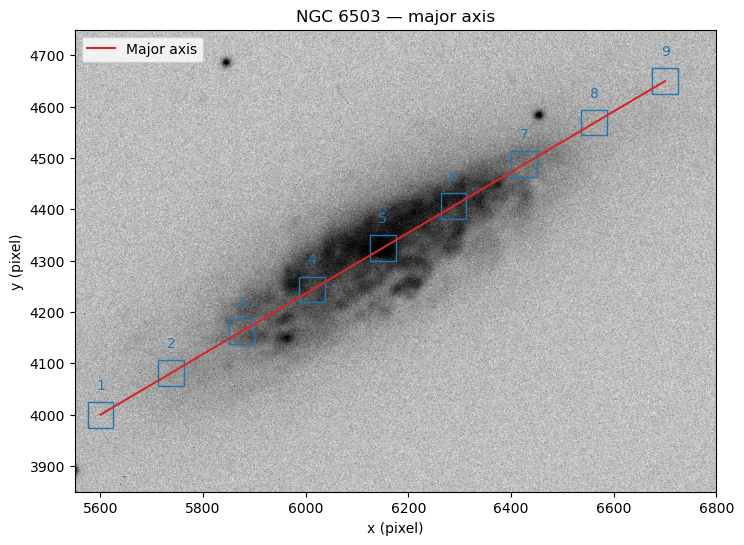

Box centers (x, y):
 [[5600 4000]
 [5738 4081]
 [5875 4162]
 [6012 4244]
 [6150 4325]
 [6288 4406]
 [6425 4488]
 [6562 4569]
 [6700 4650]]


In [14]:
# Define 9 squares along this line, roughly equidistant from each other, 
# with the outermost being slightly past the visible arms of the galaxy (about (5600, 4000) and (6700, 4650)).
# The size of each square should be something like 20 x 20.

from matplotlib.patches import Rectangle

box_size = 50
box_centers = np.rint(np.linspace(*axis_ends, 9)).astype(int)
distance = (box_centers - axis_ends.mean(axis=0)) @ (axis_vector / axis_length)

# Show the same image and line, now with the nine measurement boxes.
for number, (x, y) in enumerate(box_centers, 1):
    ax.add_patch(Rectangle((x - box_size / 2, y - box_size / 2), box_size, box_size,
                           fill=False, edgecolor="tab:blue"))
    ax.text(x, y + 50, str(number), color="tab:blue", ha="center")
display(fig)
print("Box centers (x, y):\n", box_centers)


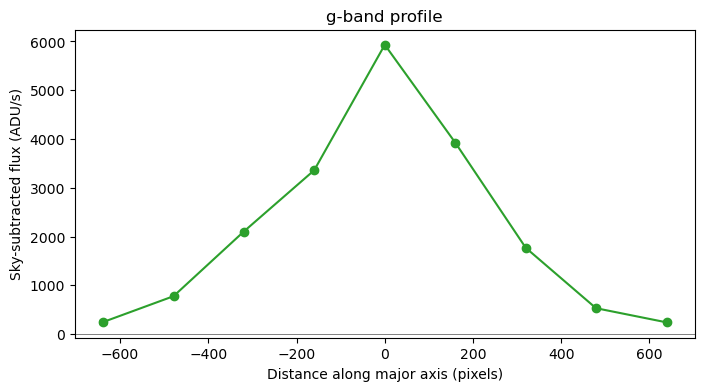

1-sigma errors use local sky-box scatter; source shot noise is omitted (gain unknown).


In [15]:
# Compute the flux along each square and plot the results. Use the g-band calibrated image for this analysis. Have error bars of one sigma.

# Estimate local sky/noise from equal-sized boxes on both sides of the galaxy.
# Without a measured gain, errors include background noise but omit source shot noise.
normal = np.array([-axis_vector[1], axis_vector[0]]) / axis_length
sky_offsets = np.r_[-np.arange(350, 951, 50), np.arange(350, 951, 50)]


def box_pixels(image, center):
    x, y = np.rint(center).astype(int)
    half = box_size // 2
    if not (half <= x <= image.shape[1] - half and half <= y <= image.shape[0] - half):
        raise ValueError("Measurement box lies outside the image.")
    return image[y - half:y + half, x - half:x + half]


def box_sum(image, center):
    pixels = box_pixels(image, center)
    valid = np.isfinite(pixels)
    if valid.mean() < 0.99:
        return np.nan
    # Scale to the common aperture area when a few detector pixels are masked.
    return np.mean(pixels[valid]) * pixels.size


def measure_profile(image, header):
    flux, error = [], []
    gain = header.get("EGAIN", header.get("GAIN"))  # electrons per ADU, if recorded
    for center in box_centers:
        sky_sums = np.array([box_sum(image, center + offset * normal)
                             for offset in sky_offsets])
        sky_sums = sky_sums[np.isfinite(sky_sums)]
        if len(sky_sums) < 5:
            raise ValueError("Too few valid sky boxes.")
        sky = np.median(sky_sums)
        scatter = 1.4826 * np.median(np.abs(sky_sums - sky))
        if scatter > 0:
            sky_sums = sky_sums[np.abs(sky_sums - sky) < 3 * scatter]
        sky, scatter = np.median(sky_sums), np.std(sky_sums, ddof=1)
        signal = box_sum(image, center) - sky
        # Noise of an aperture sum plus uncertainty in its median sky estimate.
        variance = scatter**2 * (1 + np.pi / (2 * len(sky_sums)))
        if gain is not None and float(gain) > 0:
            variance += max(signal, 0) / float(gain)
        flux.append(signal / exposure(header))
        error.append(np.sqrt(variance) / exposure(header))
    return np.array(flux), np.array(error)


profiles = {"g": measure_profile(calibrated_image, calibrated_header)}
fig, ax = plt.subplots(figsize=(8, 4))
ax.errorbar(distance, *profiles["g"], fmt="o-", capsize=3, color="tab:green")
ax.axhline(0, color="gray", lw=0.7)
ax.set(xlabel="Distance along major axis (pixels)", ylabel="Sky-subtracted flux (ADU/s)",
       title="g-band profile")
plt.show()
if not any(k in calibrated_header for k in ("EGAIN", "GAIN")):
    print("1-sigma errors use local sky-box scatter; source shot noise is omitted (gain unknown).")


r: NGC-6503_LIGHT_r'_1x1_120.000secs_00000120.fit


i: NGC-6503_LIGHT_i'_1x1_180.000secs_00000136.fit


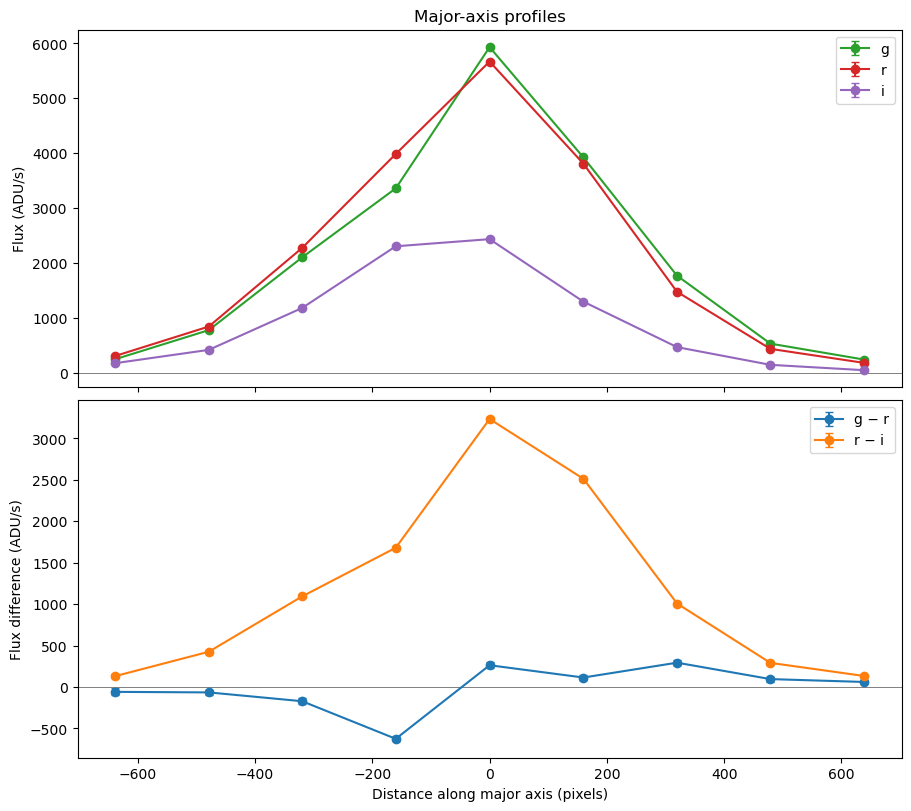

In [16]:
# Compute the same as the above cell for the r-band and i-band calibrated images. Plot both of these as well as the color flux of each.

for band in ("r", "i"):
    path = next(p for p in science_paths if science_headers[p]["FILTER"] == f"{band}'")
    band_image, band_header = calibrate_frame(path, save=True)
    profiles[band] = measure_profile(band_image, band_header)
    print(f"{band}: {path.name}")
    del band_image

fig, axes = plt.subplots(2, 1, figsize=(9, 8), sharex=True, layout="constrained")
for band, color in zip(("g", "r", "i"), ("tab:green", "tab:red", "tab:purple")):
    axes[0].errorbar(distance, *profiles[band], fmt="o-", capsize=3, color=color, label=band)

# These are flux differences, as requested; no magnitude/zero-point conversion.
color_profiles = {}
for first, second in (("g", "r"), ("r", "i")):
    flux1, error1 = profiles[first]
    flux2, error2 = profiles[second]
    difference = flux1 - flux2
    uncertainty = np.hypot(error1, error2)  # Treat the two band errors as independent.
    color_profiles[f"{first}-{second}"] = (difference, uncertainty)
    axes[1].errorbar(distance, difference, yerr=uncertainty, fmt="o-", capsize=3,
                     label=f"{first} − {second}")
for ax in axes:
    ax.axhline(0, color="gray", lw=0.7)
    ax.set_ylabel("Flux (ADU/s)")
    ax.legend()
axes[0].set_title("Major-axis profiles")
axes[1].set(xlabel="Distance along major axis (pixels)", ylabel="Flux difference (ADU/s)")
plt.show()


In [17]:
# Calibrate the data with background stars using a star solver and a database. Replot.



In [18]:
# Plot an image of the galaxy with all the boxes